# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [1]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components

## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [2]:
cache = Path("data/pbmc3k_after_pca.h5ad")
raw_folder = Path("data/filtered_gene_bc_matrices/hg19")


adata = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)

# adata = sc.datasets.pbmc3k()

In [3]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [4]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


In [5]:
adata.layers["counts"] = adata.X.copy()

In [6]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

In [7]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [8]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
AAACATACAACCAC-1,-4.729666,-0.732490,-1.319650,0.309996,-0.847278
AAACATTGAGCTAC-1,-0.771727,7.029481,4.317741,-1.829952,-1.793579
AAACATTGATCAGC-1,-3.747795,-2.741886,-2.263509,-3.970423,-1.300579
AAACCGTGCTTCCG-1,13.714340,0.483005,1.592889,-0.528095,1.163537
AAACCGTGTATGCG-1,-3.042020,-4.998931,7.369822,5.631866,1.837032


# 2. От точек к графу: kNN 

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$. 

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [9]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [11]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [12]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58154
Матрица distances: (2638, 2638) ненулевых элементов: 36932


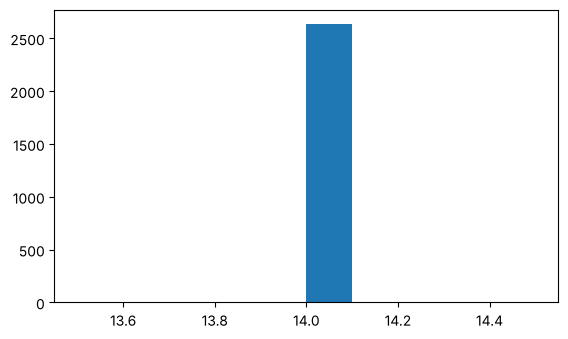

Минимум / медиана / максимум степеней: 14 14.0 14


In [13]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

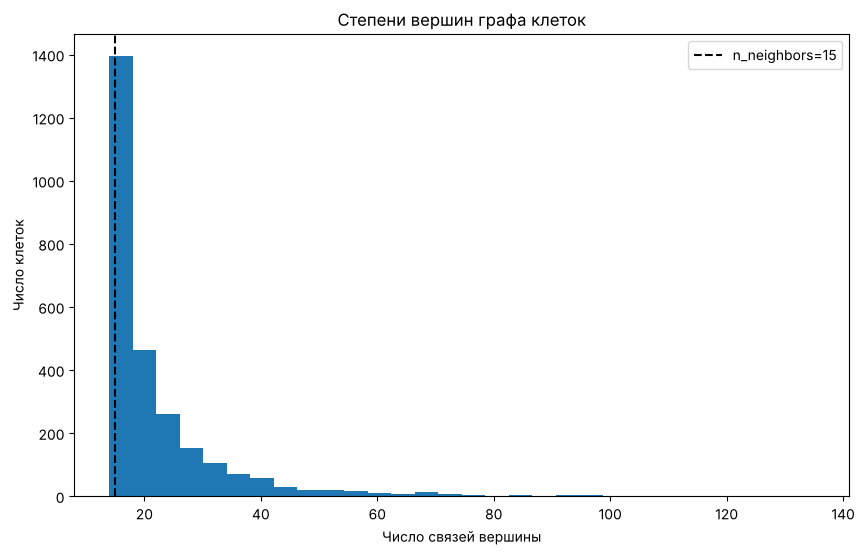

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [14]:
degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/tmp/ipykernel_611/1703150331.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")


/tmp/ipykernel_611/1703150331.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")


/tmp/ipykernel_611/1703150331.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")


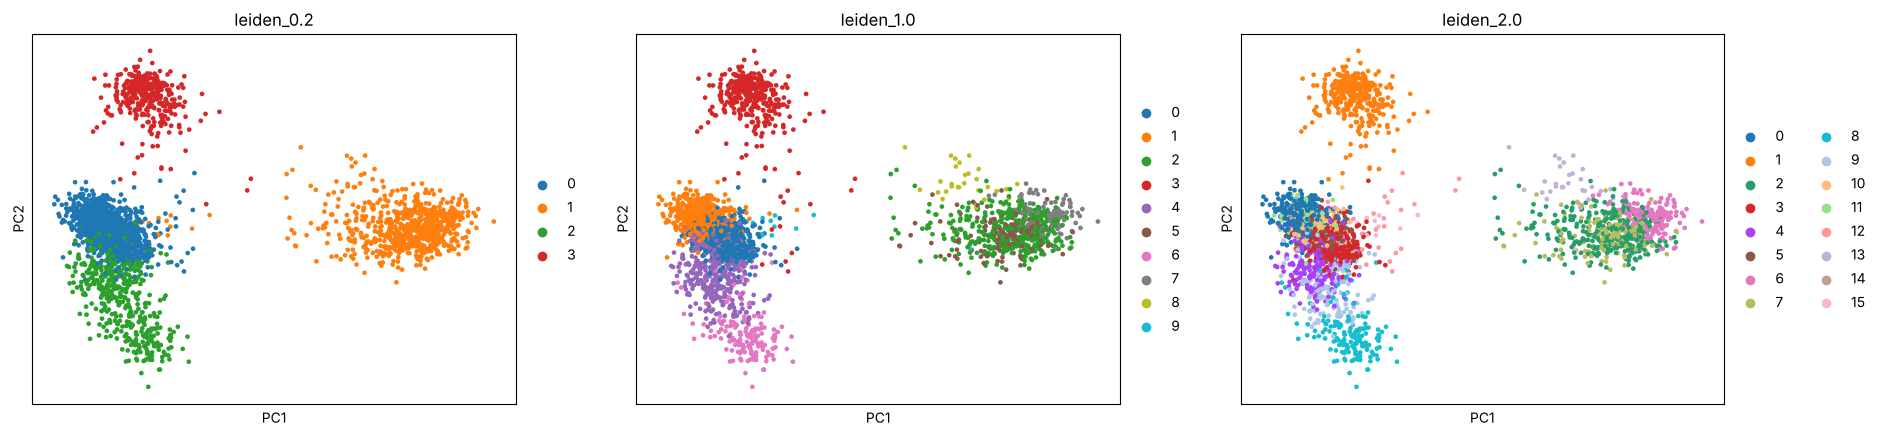

leiden_1.0
0    551
1    544
2    378
3    354
4    349
5    157
6    156
7    107
8     30
9     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

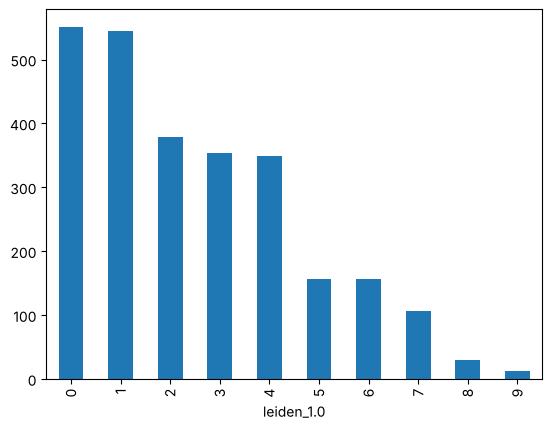

In [15]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP 

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [16]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

In [17]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


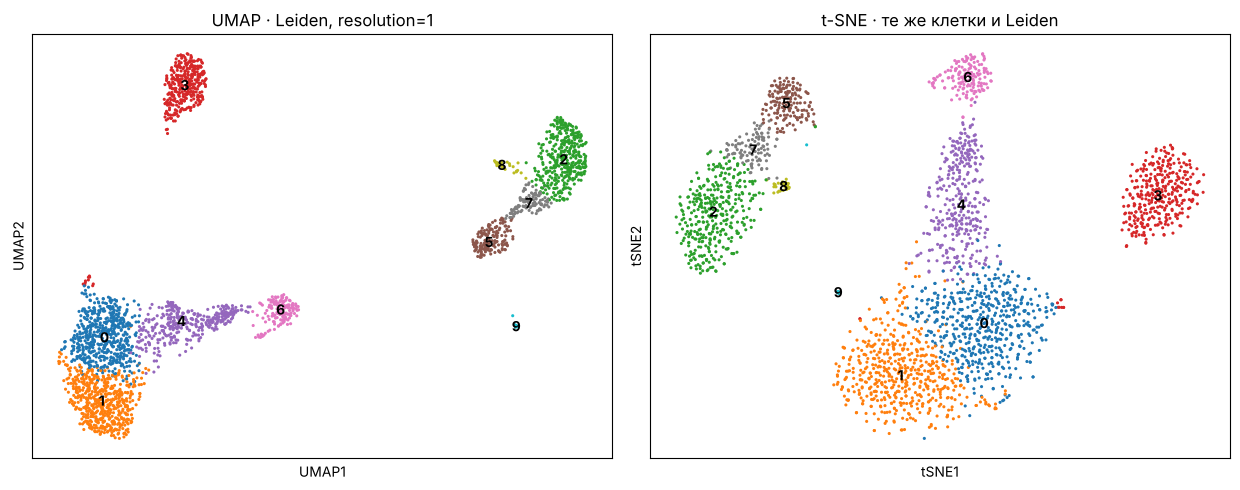

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

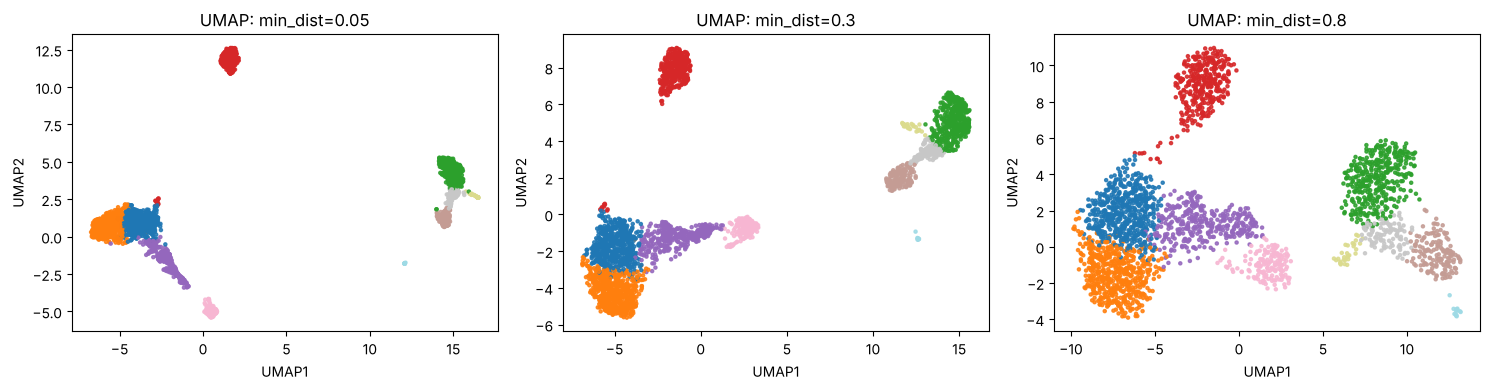

In [19]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [20]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

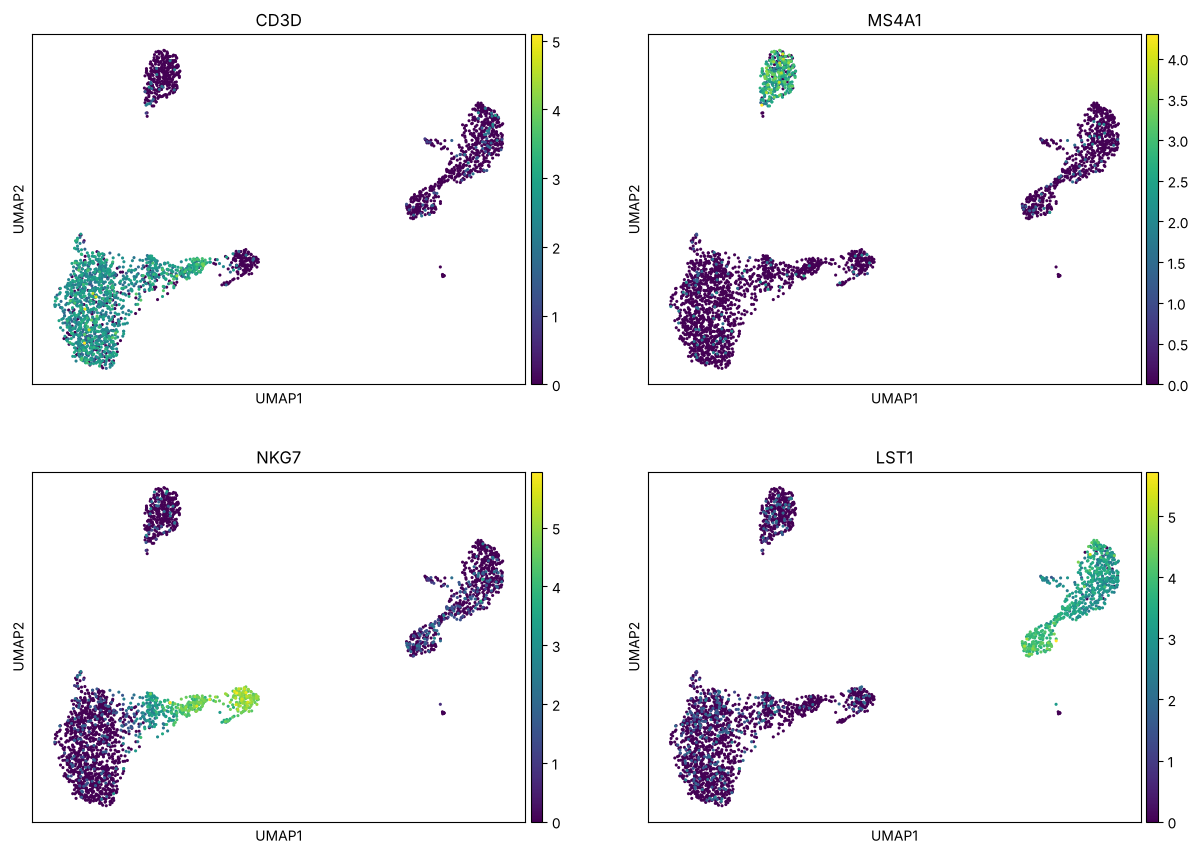

In [21]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [22]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.

![Граф из 9 вершин](seminar6_modularity_graph.png)

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.
2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).
3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


# Решение самостоятельной работы

## Задание 1. Модулярность вручную

**Рёбра графа** (по рисунку):

- внутри A: 1–2, 1–3, 2–3;
- внутри B: 4–5, 4–6, 5–6;
- внутри C: 7–8, 7–9, 8–9;
- между сообществами (пунктир): 3–4, 6–7, 1–9.

**1. Число рёбер:** $m = 9 + 3 = 12$, $2m = 24$.

**2. Рёбра внутри сообществ и суммы степеней:**

| Сообщество | $l_c$ | степени вершин | $d_c$ |
|---|---|---|---|
| A = {1,2,3} | 3 | $k_1=3,\ k_2=2,\ k_3=3$ | 8 |
| B = {4,5,6} | 3 | $k_4=3,\ k_5=2,\ k_6=3$ | 8 |
| C = {7,8,9} | 3 | $k_7=3,\ k_8=2,\ k_9=3$ | 8 |

Проверка: $\sum_c d_c = 24 = 2m$.

**3. Модулярность:**

$$
\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2=\frac{3}{12}-\left(\frac{8}{24}\right)^2=0.25-0.1111=0.1389=\frac{5}{36}
$$

Все три сообщества устроены одинаково, поэтому

$$
Q = 3\cdot\frac{5}{36}=\frac{5}{12}\approx \mathbf{0.417}.
$$

**4. Смысл второго члена.** $l_c/m$ — наблюдаемая доля рёбер внутри сообщества. $(d_c/2m)^2$ — ожидаемая доля таких рёбер, если соединить вершины случайно с сохранением их степеней (конфигурационная модель): вершины с большой суммарной степенью даже при случайном соединении часто окажутся связаны друг с другом. Без вычитания любое крупное сообщество выглядело бы «хорошим» (например, все вершины в одном сообществе дают $l_c/m = 1$, а с вычитанием $Q = 1 - 1 = 0$).

**Положительное $Q$** означает, что внутри сообществ рёбер больше, чем ожидается случайно, то есть разбиение отражает реальную структуру графа. **$Q$ не является вероятностью:** это разность двух долей. Она может быть отрицательной (разбиение хуже случайного), а максимум меньше 1 и зависит от графа.

In [23]:
# Проверка расчёта кодом
from collections import Counter
import networkx as nx

edges = [(1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (5, 6), (7, 8), (7, 9), (8, 9),   # внутри сообществ
         (3, 4), (6, 7), (1, 9)]                                                    # между сообществами
communities = {"A": {1, 2, 3}, "B": {4, 5, 6}, "C": {7, 8, 9}}

m = len(edges)
degree = Counter(v for e in edges for v in e)
Q = 0
for name, nodes in communities.items():
    l_c = sum(u in nodes and v in nodes for u, v in edges)
    d_c = sum(degree[v] for v in nodes)
    term = l_c / m - (d_c / (2 * m)) ** 2
    print(f"{name}: l_c={l_c}, d_c={d_c}, вклад = {l_c}/{m} - ({d_c}/{2*m})^2 = {term:.4f}")
    Q += term
print(f"m = {m},  Q = {Q:.4f}")
print("networkx:", round(nx.community.modularity(nx.Graph(edges), communities.values()), 4))

A: l_c=3, d_c=8, вклад = 3/12 - (8/24)^2 = 0.1389
B: l_c=3, d_c=8, вклад = 3/12 - (8/24)^2 = 0.1389
C: l_c=3, d_c=8, вклад = 3/12 - (8/24)^2 = 0.1389
m = 12,  Q = 0.4167
networkx: 0.4167


## Задание 2. Анализ клеток сердца эмбриона мыши E18 (1k cells, v3)

Набор: [1k Heart Cells from an E18 mouse (v3 chemistry)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0), файл **Feature / cell matrix HDF5 (filtered)** (`heart_1k_v3_filtered_feature_bc_matrix.h5`), положен в `data/`.

Чтобы не перезаписать `adata` с PBMC, объект называется `heart`.

In [24]:
heart = sc.read_10x_h5("data/heart_1k_v3_filtered_feature_bc_matrix.h5")
heart.var_names_make_unique()
heart

/usr/local/lib/python3.13/site-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 1011 × 31053
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

### 2.1. QC

У мыши митохондриальные гены начинаются с `mt-`. Дополнительно считаем долю гемоглобинов (`Hba-*`, `Hbb-*`): в эмбриональном сердце много крови, и эти клетки нужно отличать от прочих.

In [25]:
heart.var["mt"] = heart.var_names.str.startswith("mt-")
heart.var["hb"] = heart.var_names.str.match(r"^Hb[ab]-")
print("mt-генов:", heart.var.mt.sum(), "| Hb-генов:", heart.var.hb.sum())

sc.pp.calculate_qc_metrics(heart, qc_vars=["mt", "hb"], percent_top=None, inplace=True)
QC = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
heart.obs[QC + ["pct_counts_hb"]].describe(percentiles=[.01, .05, .5, .95, .99]).round(1)

mt-генов: 13 | Hb-генов: 8


,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_hb
count,1011.0,1011.0,1011.0,1011.0
mean,13986.7,2620.7,14.3,13.3
std,15786.7,2152.6,17.3,32.8
min,506.0,17.0,0.0,0.0
1%,609.1,35.0,0.0,0.0
5%,789.0,63.5,0.0,0.0
50%,7610.0,2058.0,7.2,0.0
95%,46641.0,6357.0,50.5,96.7
99%,67060.0,7547.5,83.0,98.1
max,122022.0,9452.0,99.0,98.6


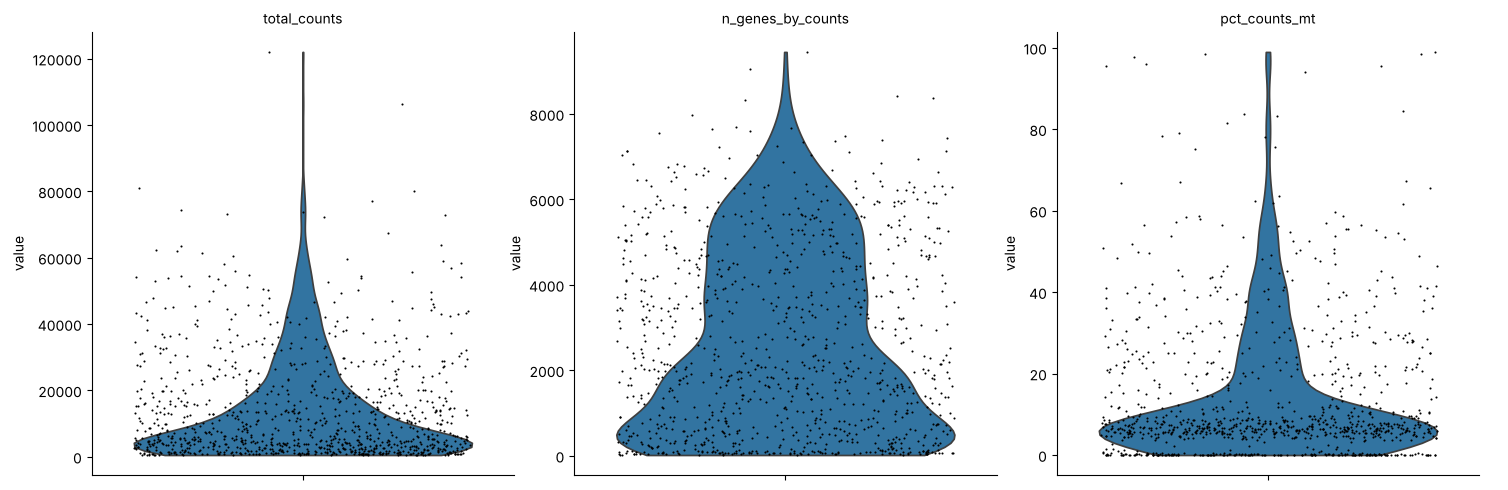

In [26]:
sc.pl.violin(heart, QC, multi_panel=True, jitter=0.4, size=1.5)

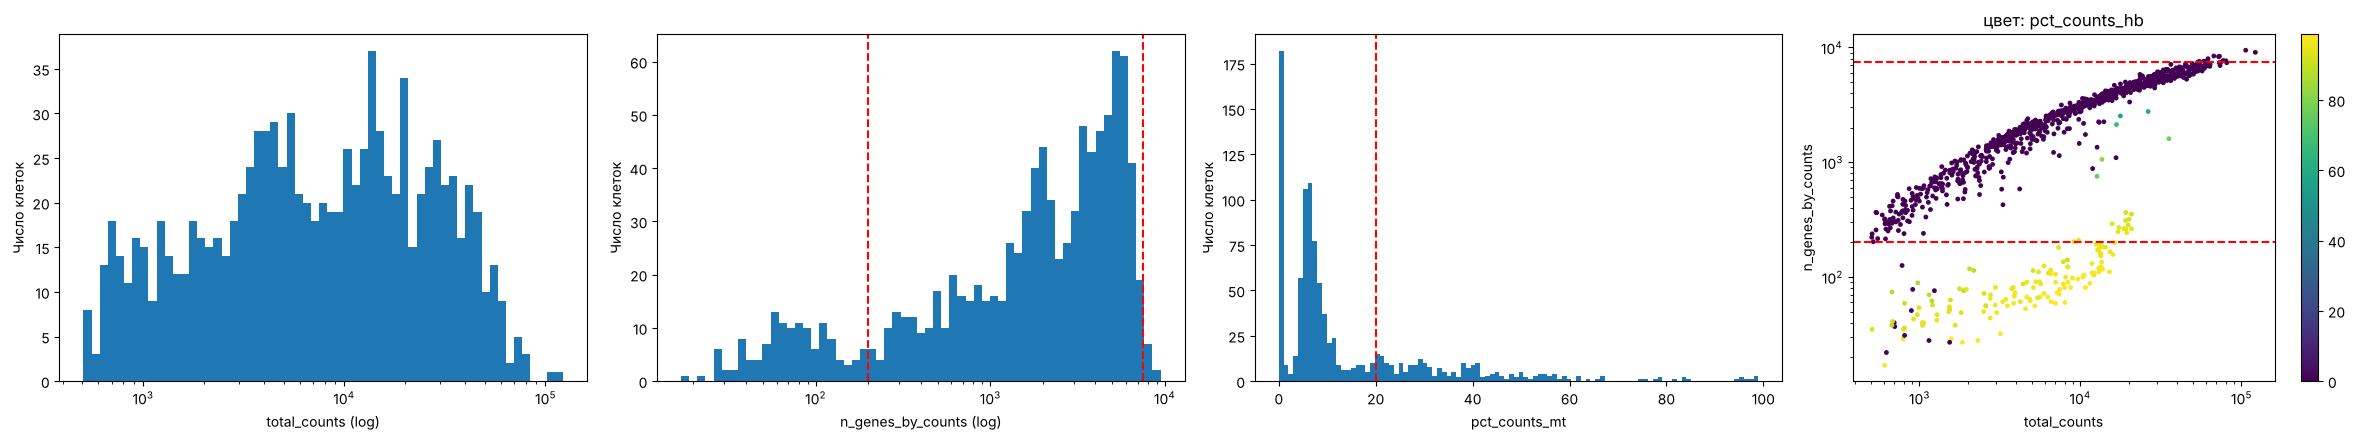

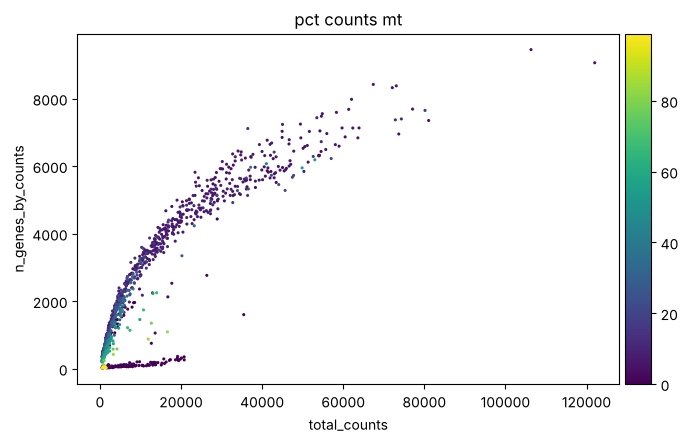

In [27]:
# Пороги (обоснование — ниже)
MIN_GENES = 200     # нижний порог числа генов
MAX_GENES = 7500    # ≈ 99-й перцентиль: отсекаем ~1% кандидатов в дублеты
MAX_MT = 20         # % митохондриальных UMI
MIN_CELLS = 3       # ген должен встречаться хотя бы в 3 клетках

o = heart.obs
fig, axes = plt.subplots(1, 4, figsize=(24, 4.5))
axes[0].hist(o.total_counts, bins=np.geomspace(o.total_counts.min(), o.total_counts.max(), 60))
axes[0].set(xscale="log", xlabel="total_counts (log)", ylabel="Число клеток")
axes[1].hist(o.n_genes_by_counts, bins=np.geomspace(o.n_genes_by_counts.min(), o.n_genes_by_counts.max(), 60))
axes[1].set(xscale="log", xlabel="n_genes_by_counts (log)", ylabel="Число клеток")
for t in (MIN_GENES, MAX_GENES):
    axes[1].axvline(t, color="red", ls="--")
axes[2].hist(o.pct_counts_mt, bins=100)
axes[2].axvline(MAX_MT, color="red", ls="--")
axes[2].set(xlabel="pct_counts_mt", ylabel="Число клеток")
s = axes[3].scatter(o.total_counts, o.n_genes_by_counts, c=o.pct_counts_hb, s=6, cmap="viridis")
axes[3].axhline(MIN_GENES, color="red", ls="--"); axes[3].axhline(MAX_GENES, color="red", ls="--")
axes[3].set(xscale="log", yscale="log", xlabel="total_counts", ylabel="n_genes_by_counts", title="цвет: pct_counts_hb")
plt.colorbar(s, ax=axes[3])
plt.tight_layout(); plt.show()

sc.pl.scatter(heart, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt", size=20)

In [28]:
# Кого отсекает каждый порог
low = o.n_genes_by_counts < MIN_GENES
print(f"n_genes < {MIN_GENES}: {low.sum()} клеток, медианная доля Hb у них = {o.pct_counts_hb[low].median():.1f}%")
print(f"n_genes > {MAX_GENES}: {(o.n_genes_by_counts > MAX_GENES).sum()} клеток")

# Доля mt по диапазонам: сколько клеток и сколько генов они содержат
ok = ~low
bins = pd.cut(o.pct_counts_mt[ok], [0, 5, 10, 20, 30, 50, 100], include_lowest=True)
o[ok].groupby(bins, observed=True).agg(клеток=("total_counts", "size"),
                                       медиана_генов=("n_genes_by_counts", "median"),
                                       медиана_UMI=("total_counts", "median")).round(0)

n_genes < 200: 132 клеток, медианная доля Hb у них = 95.9%
n_genes > 7500: 11 клеток


,клеток,медиана_генов,медиана_UMI
pct_counts_mt,,,
"(-0.001, 5.0]",146,2046.0,15474.0
"(5.0, 10.0]",382,4070.0,17292.0
"(10.0, 20.0]",109,2170.0,5408.0
"(20.0, 30.0]",96,1480.0,3526.0
"(30.0, 50.0]",104,662.0,1738.0
"(50.0, 100.0]",42,682.0,2618.0


In [29]:
n_before = heart.n_obs
sc.pp.filter_cells(heart, min_genes=MIN_GENES)
sc.pp.filter_genes(heart, min_cells=MIN_CELLS)
heart = heart[(heart.obs.n_genes_by_counts < MAX_GENES) & (heart.obs.pct_counts_mt < MAX_MT)].copy()
print(f"Клеток до QC: {n_before}, после QC: {heart.n_obs}  (удалено {n_before - heart.n_obs})")
print(f"Генов после фильтрации: {heart.n_vars}")

Клеток до QC: 1011, после QC: 625  (удалено 386)
Генов после фильтрации: 16619


**Выбор порогов.** 

- **`min_genes = 200`.** На scatter видны две отдельные ветви. В нижней (меньше ~200–300 генов при тысячах UMI) почти все UMI приходятся на гемоглобин: медианная доля Hb = 95.9 %. Это **эритроциты**: у них нет ядра, и почти весь транскриптом — это `Hba`/`Hbb`. Порог 200 убирает 132 такие клетки вместе с немногими действительно пустыми каплями. Эритроциты — это кровь в сосудах сердца, а не клетки ткани. К тому же из-за почти нулевой сложности транскриптома они плохо нормализуются. Часть эритроцитов (~20 клеток) чуть выше порога осталась и дальше образует отдельный кластер.
- **`max_genes = 7500`** (≈ 99-й перцентиль) убирает 11 клеток с максимальным числом генов. По оценке 10x, при ~1000 клетках доля дублетов около 0.8 %, поэтому верхний 1 % — разумная оценка кандидатов в дублеты. Отдельного «облака» дублетов на scatter нет, поэтому сильнее порог не ужесточаем.
- **`max_mt = 20 %`.** Порог с PBMC (5 %) здесь не подходит: основной пик распределения находится на 5–10 %, и при 5 % осталось бы лишь 146 клеток. В сердце много митохондрий, и такая доля нормальна. Таблица выше показывает, что после 20 % резко падает качество клеток: медианное число генов снижается с ~4000 (5–10 % mt) до ~1500 (20–30 %) и ~660 (30–50 %). Такие клетки похожи на повреждённые, у которых вытекла цитоплазматическая мРНК. Цена порога — потеря части кардиомиоцитов: их и так мало, и при диссоциации они повреждаются чаще других клеток.
- **`min_cells = 3`** для генов — как на семинаре: ген, встреченный в 1–2 клетках, не помогает разделить популяции.
- **Итог:** из 1011 клеток осталось **625**, генов — 16 619.

### 2.2. Нормализация, log1p и HVG

HVG: 2000 из 16619


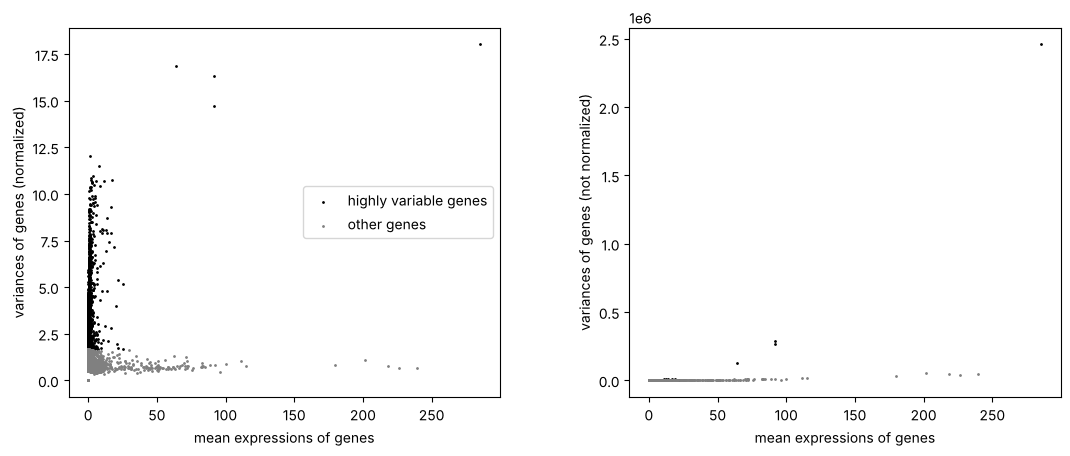

In [30]:
heart.layers["counts"] = heart.X.copy()
sc.pp.highly_variable_genes(heart, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pp.normalize_total(heart, target_sum=1e4)
sc.pp.log1p(heart)
print("HVG:", heart.var.highly_variable.sum(), "из", heart.n_vars)
sc.pl.highly_variable_genes(heart)

**Почему HVG и почему 2000.** Отобрано **2000 HVG** из 16 619 генов (`seurat_v3` по сырым counts). Большинство генов в отдельной клетке экспрессируются слабо или ровно во всех клетках: их вариация — технический шум, который размывает PCA (см. семинар 1, задания 3 и 4). HVG оставляют гены, вариабельность которых превышает ожидаемую при их среднем уровне, — именно они различают типы клеток. 2000 — стандартный компромисс для ~600 клеток. Этого достаточно, чтобы захватить маркеры даже небольших популяций (кардиомиоциты, эпикард, эпителий тимуса), а шумовых генов попадает не так много. Если сильно уменьшить число генов (до ~500), можно потерять маркеры редких групп; если сильно увеличить (до 5000+), вернётся шум.

### 2.3. PCA

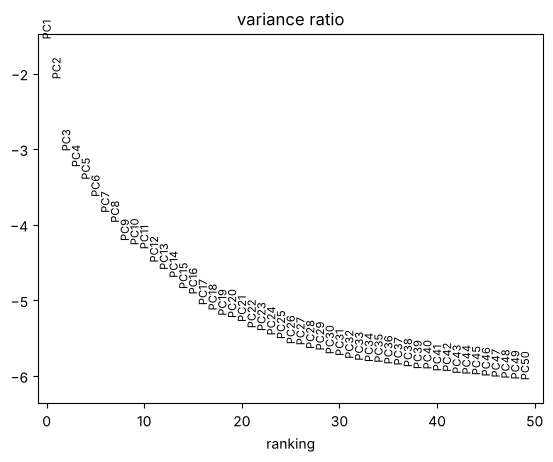

Доля дисперсии PC1–PC20, %: [21.26 12.55  4.84  3.93  3.32  2.65  2.14  1.88  1.48  1.4   1.32  1.11
  1.01  0.91  0.78  0.73  0.63  0.59  0.55  0.53]
Суммарно первые 15 PC: 60.6%


In [31]:
sc.tl.pca(heart, n_comps=50, mask_var="highly_variable", random_state=42)
sc.pl.pca_variance_ratio(heart, n_pcs=50, log=True)

vr = heart.uns["pca"]["variance_ratio"]
print("Доля дисперсии PC1–PC20, %:", np.round(vr[:20] * 100, 2))
N_PCS = 15
print(f"Суммарно первые {N_PCS} PC: {vr[:N_PCS].sum():.1%}")

**Выбор числа компонент.** PC1 и PC2 объясняют 21 % и 13 % дисперсии, PC3–PC8 — от 5 % до 2 %. Дальше кривая выходит на пологий хвост: начиная с ~PC13–15 каждая компонента добавляет < 1 %, и вклад убывает медленно. Это и есть «локоть». Беру **15 PC**, они вместе объясняют 60.6 % дисперсии HVG. Небольшой запас после локтя не вредит (компоненты с шумом слабо влияют на расстояния), а мелкие популяции, которые описываются поздними PC, не теряются.

### 2.4. Граф соседей и Leiden

In [32]:
N_NEIGHBORS = 15
RESOLUTION = 0.5

sc.pp.neighbors(heart, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS, random_state=42)
# flavor="igraph" — рекомендованная реализация Leiden в Scanpy (станет вариантом по умолчанию)
for r in (0.3, RESOLUTION, 1.0):
    sc.tl.leiden(heart, resolution=r, key_added=f"leiden_{r}", flavor="igraph",
                 n_iterations=2, directed=False, random_state=0)
    print(f"resolution={r}: {heart.obs[f'leiden_{r}'].nunique()} кластеров")

heart.obs["leiden"] = heart.obs[f"leiden_{RESOLUTION}"]
heart.obs["leiden"].value_counts().sort_index().rename("клеток").to_frame().T

resolution=0.3: 10 кластеров
resolution=0.5: 12 кластеров
resolution=1.0: 15 кластеров


leiden,0,1,2,3,4,5,6,7,8,9,10,11
клеток,82,130,84,35,83,42,20,52,21,29,24,23


**Параметры.** 

- **`n_pcs = 15`** — выбрано по графику PCA.
- **`n_neighbors = 15`** — стандартное значение, как на семинаре. Для 625 клеток это примерно 2.5 % выборки на вершину: граф остаётся локальным, но самые маленькие популяции (20–30 клеток) всё ещё могут образовать собственную связную группу. При больших значениях они бы «прилипали» к соседям.
- **`resolution = 0.5`.** Небольшие, явно разные группы (кардиомиоциты двух типов, фибробласты, эндотелий, эпикард, эритроциты, эпителий тимуса) выделяются отдельными кластерами уже при 0.3. Дальше `resolution` в основном дробит большое облако T-клеток: 3 части при 0.3, 5 при 0.5 и 7 при 1.0. При 1.0 начинают делиться и небольшие группы, появляются кластеры по 14–15 клеток. При 0.5 отделяются делящиеся группы (кластеры 2 и 4, `Top2a`⁺), и это уже интерпретируемо. Дальнейшее дробление непрерывного облака не даёт новых различимых групп, поэтому выбираю 0.5.
- **Итог:** **12 кластеров**, размеры от 20 до 130 клеток (таблица выше).

### 2.5. UMAP и t-SNE

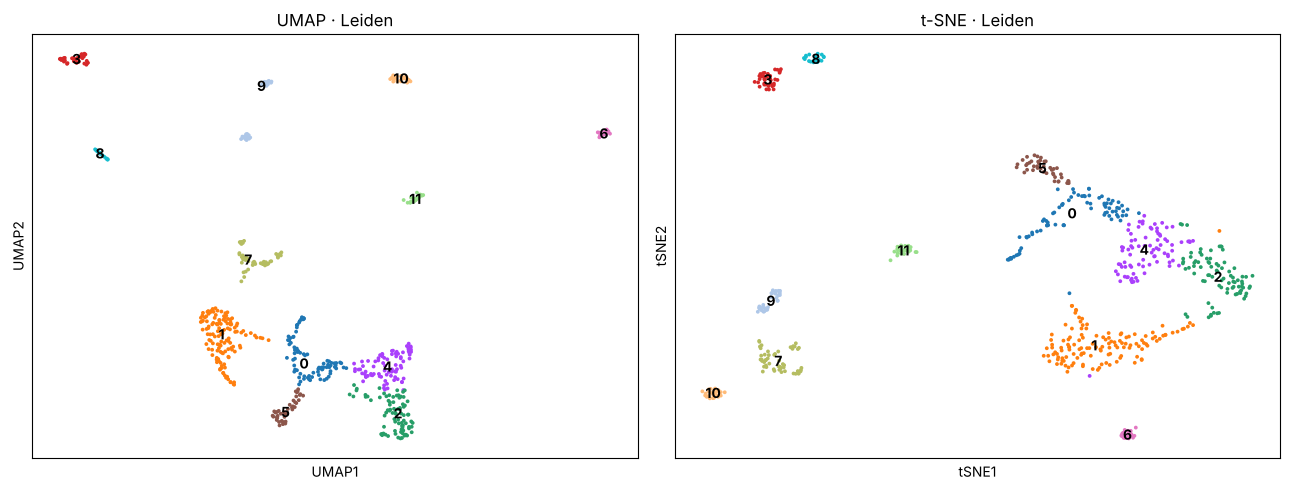

In [33]:
sc.tl.umap(heart, min_dist=0.3, random_state=42)
sc.tl.tsne(heart, use_rep="X_pca", n_pcs=N_PCS, perplexity=30, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc.pl.umap(heart, color="leiden", legend_loc="on data", ax=axes[0], show=False, size=30, title="UMAP · Leiden")
sc.pl.tsne(heart, color="leiden", legend_loc="on data", ax=axes[1], show=False, size=30, title="t-SNE · Leiden")
plt.tight_layout(); plt.show()

Окраска по QC-метрике и двум известным генам:

- `Tnnt2` — сердечный тропонин T, классический маркер кардиомиоцитов;
- `Cd3e` — субъединица T-клеточного рецепторного комплекса, маркер T-клеток.

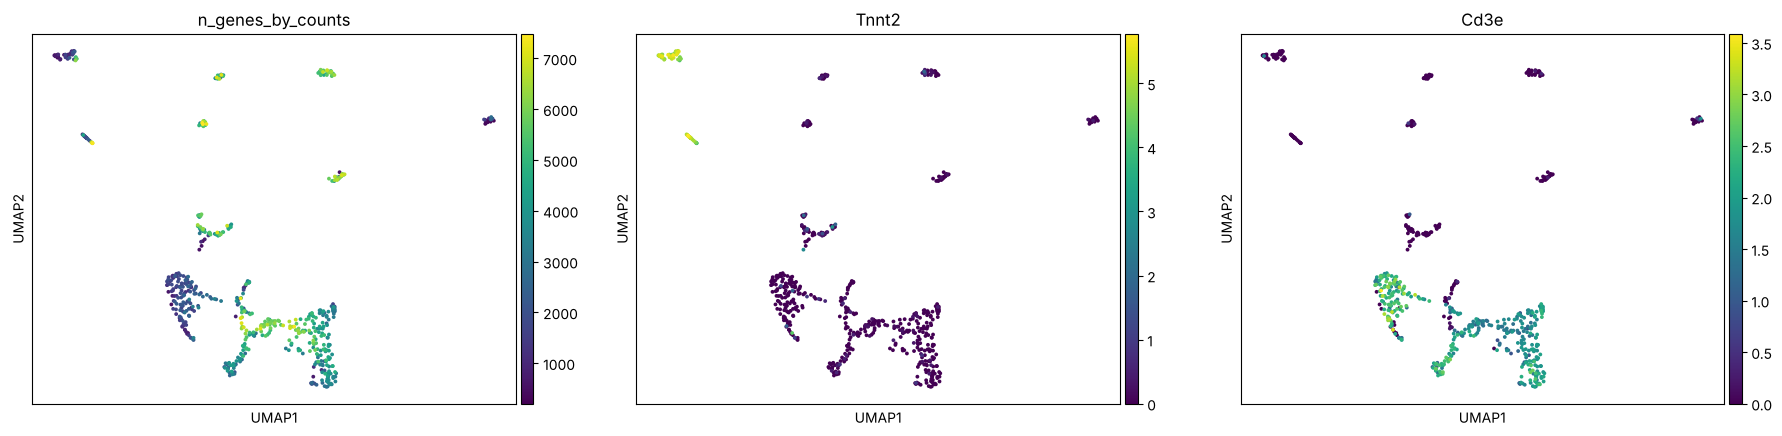

In [34]:
sc.pl.umap(heart, color=["n_genes_by_counts", "Tnnt2", "Cd3e"], ncols=3, size=30)

**Что видно и чего сказать нельзя.** 

- Обе карты дают одинаковое разбиение: компактные изолированные группы (кластеры 3, 6, 7, 8, 9, 10, 11) и одно крупное непрерывное облако из кластеров 0, 1, 2, 4, 5. Метки Leiden на обеих картах не перемешиваются, значит кластеры согласуются со структурой графа.
- `Tnnt2` экспрессируется только в кластерах 3 и 8. `Cd3e` — во всём большом облаке, то есть больше половины клеток после QC относятся к T-линии.
- Число генов (QC-метрика) распределено неравномерно: внутри облака T-клеток есть участок с высоким `n_genes`, а кластер 1 — с низким. Часть деления облака может быть связана с глубиной и активностью клеток, а не только с подтипом.
- **Чего сказать нельзя:**
  - расстояния между изолированными группами и их взаимное расположение на UMAP/t-SNE ничего не значат: например, нельзя утверждать, что эндотелий «ближе» к кардиомиоцитам, чем к фибробластам;
  - размер и плотность пятна не отражают размер популяции и её разнообразие;
  - форма облака тимоцитов («ветви», «мостики») не доказывает траекторию развития;
  - число кластеров зависит от `resolution`, и границы внутри непрерывного облака условны.

### 2.6. Биологический вывод

Гены для проверки гипотез выбраны по литературе (известные маркеры), без автоматического поиска:

| Гипотеза | Гены |
|---|---|
| Кардиомиоциты (желудочковые / предсердные) | `Tnnt2`, `Myl2` / `Myl7`, `Nppa` |
| Фибробласты | `Col1a1`, `Postn` |
| Эндотелий | `Cdh5`, `Pecam1` |
| Эпикард | `Wt1`, `Upk3b` |
| Эритроциты | `Hba-a1`, `Hbb-bt` |
| Тимоциты (T-клетки тимуса) | `Cd3e`, `Cd8a`, `Cd4`, `Rag1` |
| Делящиеся клетки | `Top2a` |
| Эпителий тимуса | `Krt8`, `Prss16` |

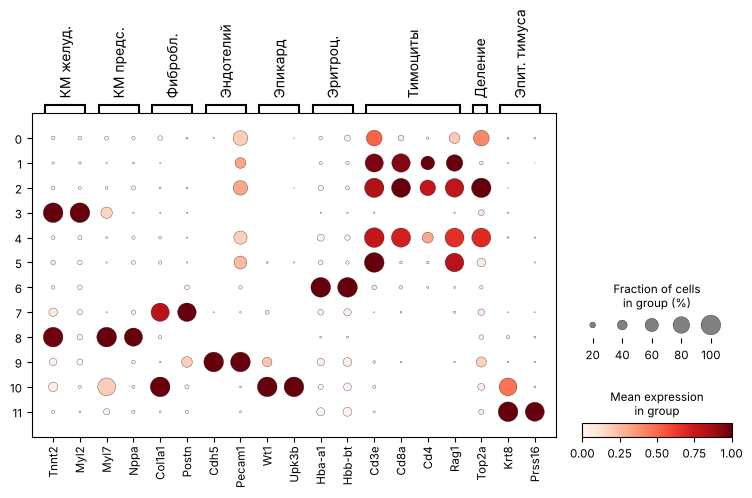

In [35]:
marker_panel = {
    "КМ желуд.": ["Tnnt2", "Myl2"],
    "КМ предс.": ["Myl7", "Nppa"],
    "Фибробл.": ["Col1a1", "Postn"],
    "Эндотелий": ["Cdh5", "Pecam1"],
    "Эпикард": ["Wt1", "Upk3b"],
    "Эритроц.": ["Hba-a1", "Hbb-bt"],
    "Тимоциты": ["Cd3e", "Cd8a", "Cd4", "Rag1"],
    "Деление": ["Top2a"],
    "Эпит. тимуса": ["Krt8", "Prss16"],
}
sc.pl.dotplot(heart, marker_panel, groupby="leiden", standard_scale="var")

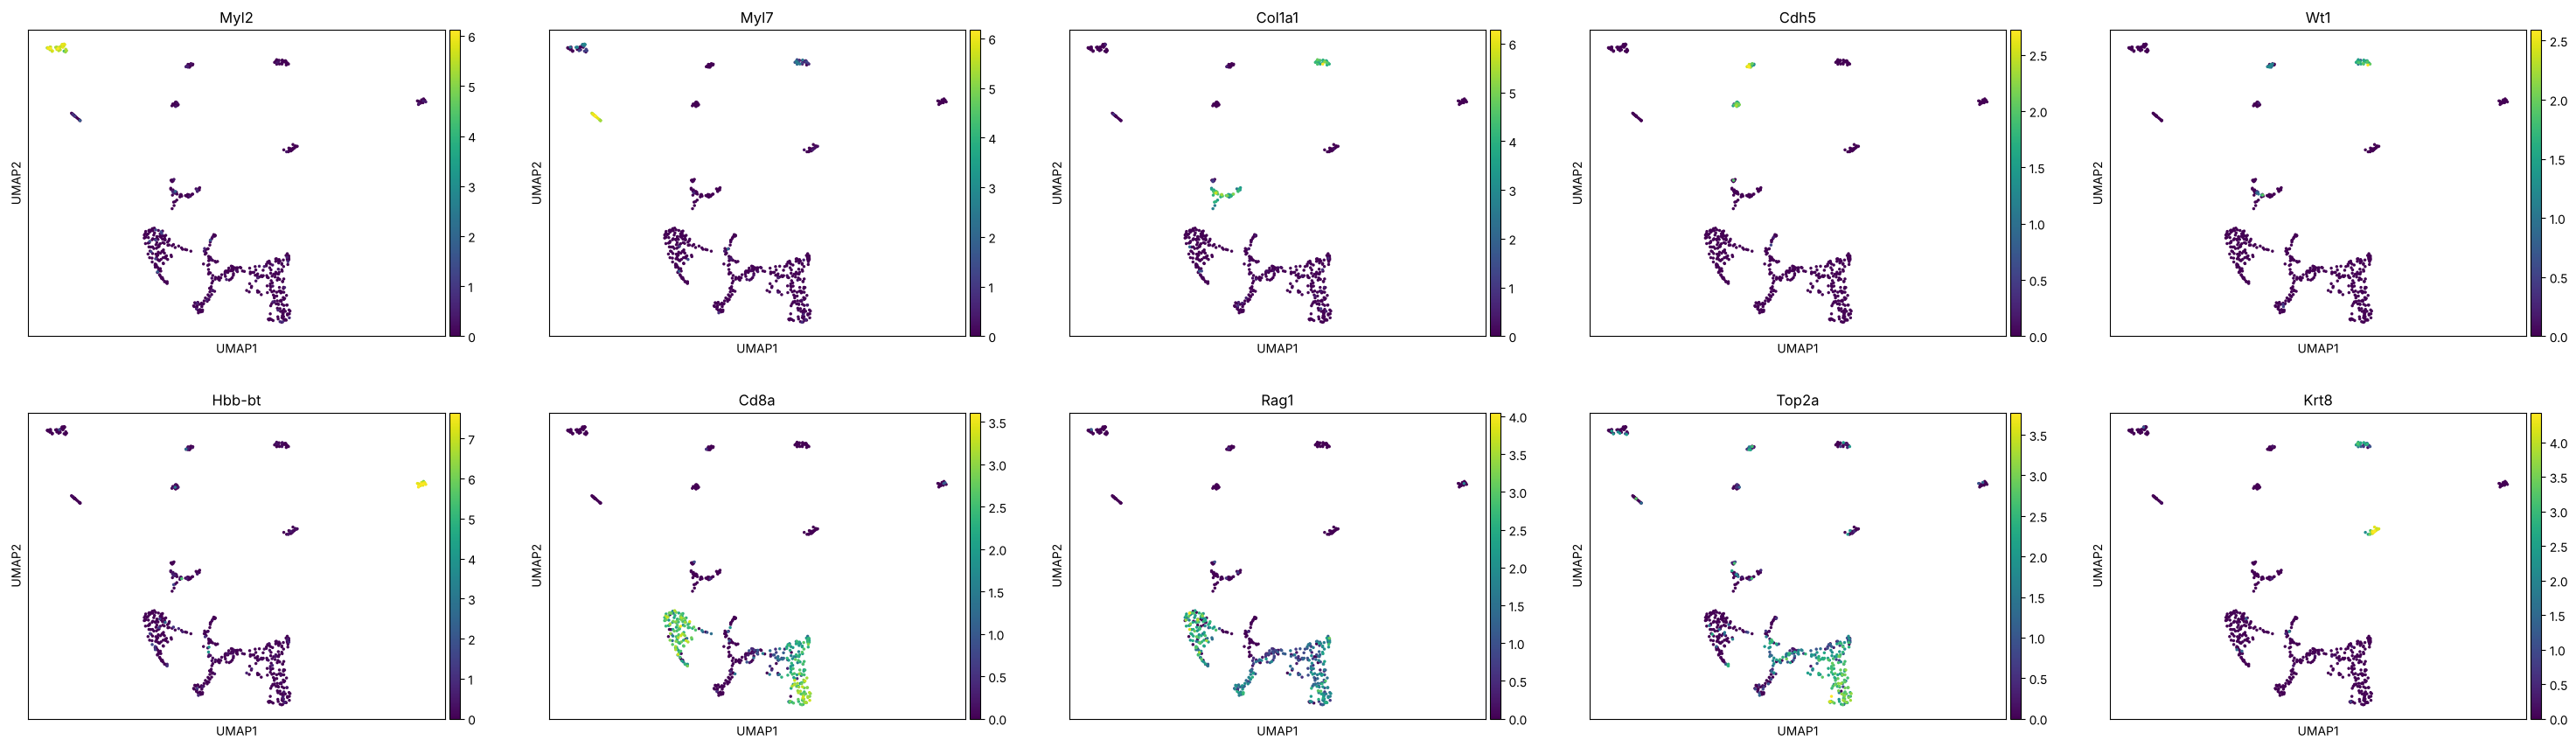

In [36]:
sc.pl.umap(heart, color=["Myl2", "Myl7", "Col1a1", "Cdh5", "Wt1", "Hbb-bt", "Cd8a", "Rag1", "Top2a", "Krt8"],
           ncols=5, size=25)

**Предполагаемые популяции.** Выводы предположительные: они опираются на экспрессию заранее выбранных известных генов, а не на строгую аннотацию.

- **Кластер 3 — желудочковые кардиомиоциты** (`Tnnt2`⁺, `Myl2`⁺). **Кластер 8 — предсердные кардиомиоциты** (`Tnnt2`⁺, `Myl7`⁺, `Nppa`⁺). Деление на желудочковые и предсердные согласуется с известными маркерами камер сердца. Кардиомиоцитов мало (56 клеток), вероятно, потому что крупные клетки хуже переживают диссоциацию и частично ушли на QC.
- **Кластер 7 — фибробласты** (`Col1a1`⁺, `Postn`⁺).
- **Кластер 9 — эндотелий** (`Cdh5`⁺, `Pecam1`⁺).
- **Кластер 10 — эпикард** (`Wt1`⁺, `Upk3b`⁺, а также `Col1a1`): мезотелиальная оболочка сердца, из которой происходят фибробласты.
- **Кластер 6 — эритроциты** (`Hba-a1`⁺, `Hbb-bt`⁺): кровь, оставшаяся в образце.
- **Кластеры 0, 1, 2, 4, 5 — T-клетки**, предположительно **тимоциты** (`Cd3e`⁺). В кластерах 1, 2 и 4 одновременно экспрессируются `Cd8a` и `Cd4` и высок `Rag1`, то есть идёт перестройка T-клеточного рецептора. Такое сочетание типично для незрелых double-positive тимоцитов, а не для зрелых T-клеток крови. В кластерах 2 и 4 высок `Top2a`: это делящиеся клетки, и разбиение облака частично отражает фазу клеточного цикла.
- **Кластер 11 — эпителий тимуса** (`Krt8`⁺, `Prss16`⁺; `Prss16` — маркер кортикального эпителия тимуса).
- **Главный вывод:** присутствие тимоцитов и эпителия тимуса — это, скорее всего, **примесь тимуса**. У мыши он прилегает к основанию сердца и мог попасть в образец при выделении. Поэтому реальный клеточный состав сердца здесь — это кардиомиоциты, фибробласты, эндотелий и эпикард, а больше половины клеток набора к сердцу, вероятно, не относятся. Проверить гипотезу можно, сравнив с другим набором сердца (например, `heart_10k_v3`) или посмотрев гены зрелости T-клеток.